In [1]:
import pandas as pd
import sqlite3

In [2]:
conn=sqlite3.connect("../data/checking-logs.sqlite")

In [3]:
df=pd.read_sql("select datetime from pageviews where uid like 'user_%'",conn)

df['datetime']=pd.to_datetime(df['datetime'])
df = df.groupby(df['datetime'].dt.date).size()
df = df.reset_index(name='count')
df


,datetime,count
0,2020-04-17,1
1,2020-04-18,23
2,2020-04-19,15
3,2020-04-21,3
4,2020-04-22,1
5,2020-04-23,5
6,2020-04-25,1
7,2020-04-26,8
8,2020-04-28,2
9,2020-04-29,4


In [4]:
df = df.set_index('datetime')

/tmp/ipykernel_331290/994425491.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  df_grtaph.set_xticklabels(df_grtaph.get_xticklabels(), rotation=90)


[Text(18369.0, 0, '2020-04-17'),
 Text(18373.0, 0, '2020-04-21'),
 Text(18377.0, 0, '2020-04-25'),
 Text(18381.0, 0, '2020-04-29'),
 Text(18383.0, 0, '2020-05-01'),
 Text(18387.0, 0, '2020-05-05'),
 Text(18391.0, 0, '2020-05-09'),
 Text(18395.0, 0, '2020-05-13'),
 Text(18399.0, 0, '2020-05-17'),
 Text(18403.0, 0, '2020-05-21')]

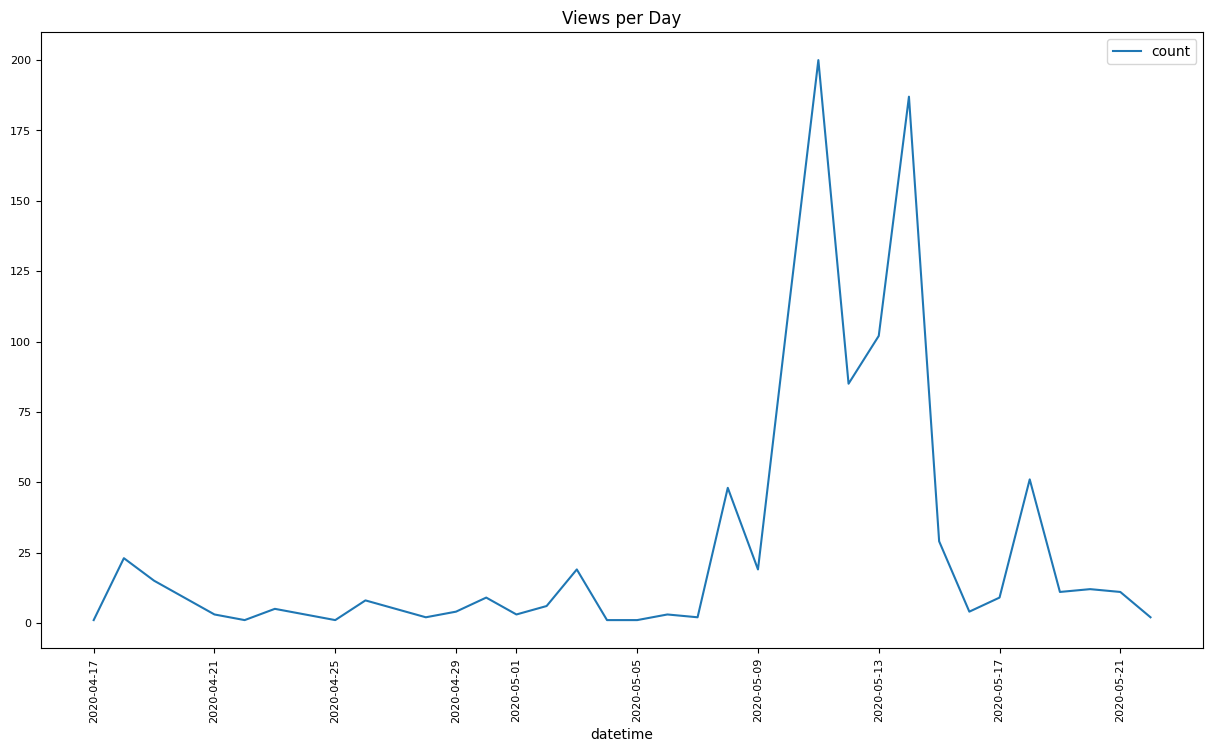

In [5]:
df_grtaph= df.plot(figsize=(15, 8), title="Views per Day", fontsize=8 )
df_grtaph.set_xticklabels(df_grtaph.get_xticklabels(), rotation=90)

In [6]:
conn.close()